In [8]:
import pandas as pd

df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")

df_train.head()

,SampleID,DAY_OF_WEEK,PIRATE_CREW,SHIP_NAME,ORIGIN_PORT,DESTINATION_PORT,SCHEDULED_DEPARTURE,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY
0,126117,2.0,Davy Jones Locker,The Wooden Mermaid II,The Drunken Storm Cove,The Eternal Pearl Depths,1948.712358,1707.477516,886.099938,138.341818
1,113108,NaN,Wicked Navigators,The Barnacle Galleon II,The Iron Ghost Bay,The Forgotten Skull Lagoon,850.823675,1313.480848,218.227913,77.119253
2,58186,1.0,Wicked Navigators,The Wooden Mermaid II,The Azure Plank Depths,The Mystic Vessel Shoals,2081.124799,2343.954344,1800.896521,109.854656
3,227295,4.0,Anchor Avengers,The Vengeful Marauder III,The Drunken Kraken Fortress,The Crimson Bone Point,734.463060,710.711336,1888.019740,90.462707
4,228331,4.0,Anchor Avengers,The Wooden Mermaid II,The Azure Bone Fortress,The Savage Compass Harbor,499.115069,1429.140029,444.815215,68.416017


In [9]:
subtask1 = df_test.DAY_OF_WEEK.isna().sum() / len(df_test) * 100

df_1 = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": [1],
    "answer": subtask1
})

df_1

,subtaskID,datapointID,answer
0,1,1,39.313966


In [10]:
def get_hour(val):
    val = int(val)
    if val < 100:
        return 0
    else:
        return int(val/100)

df_test["Hour"] = df_test.SCHEDULED_DEPARTURE.apply(get_hour)
subtask2 = df_test.groupby("PIRATE_CREW")["Hour"].apply(lambda x: x.value_counts().index[0])

df_2 = pd.DataFrame({
    "subtaskID": 2,
    "datapointID": subtask2.index,
    "answer": subtask2.values
})

df_2

,subtaskID,datapointID,answer
0,2,Abyssal Scoundrels,12
1,2,Anchor Avengers,20
2,2,Barnacle Six,14
3,2,Davy Jones Locker,22
4,2,Evil Vipers,8
5,2,Fleet of the Nine,5
6,2,High Seas Assassins,12
7,2,Marauding Quartermasters,23
8,2,Neptune's Knights,14
9,2,One-Eyed Outlaws,14


In [11]:
df_train.columns

Index(['SampleID', 'DAY_OF_WEEK', 'PIRATE_CREW', 'SHIP_NAME', 'ORIGIN_PORT',
       'DESTINATION_PORT', 'SCHEDULED_DEPARTURE', 'DISTANCE',
       'SCHEDULED_ARRIVAL', 'ARRIVAL_DELAY'],
      dtype='object')

In [12]:
#preprocessing - fill with median, target enc
target = 'ARRIVAL_DELAY'

df_train.DAY_OF_WEEK = df_train.DAY_OF_WEEK.fillna(df_train.DAY_OF_WEEK.median())
df_test.DAY_OF_WEEK = df_test.DAY_OF_WEEK.fillna(df_test.DAY_OF_WEEK.median())

from sklearn.preprocessing import TargetEncoder
to_enc = ['PIRATE_CREW', 'SHIP_NAME', 'ORIGIN_PORT', 'DESTINATION_PORT']
enc = TargetEncoder()
df_train[to_enc] = enc.fit_transform(df_train[to_enc], df_train[target])
df_test[to_enc] = enc.transform(df_test[to_enc])

df_train.head()

,SampleID,DAY_OF_WEEK,PIRATE_CREW,SHIP_NAME,ORIGIN_PORT,DESTINATION_PORT,SCHEDULED_DEPARTURE,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY
0,126117,2.0,36.182422,94.394807,45.892885,68.167134,1948.712358,1707.477516,886.099938,138.341818
1,113108,4.0,31.229635,90.528909,83.688944,-10.047910,850.823675,1313.480848,218.227913,77.119253
2,58186,1.0,31.056259,94.394807,31.992911,64.319886,2081.124799,2343.954344,1800.896521,109.854656
3,227295,4.0,33.337914,72.975394,52.597256,50.134559,734.463060,710.711336,1888.019740,90.462707
4,228331,4.0,33.636162,94.500719,46.700048,9.142007,499.115069,1429.140029,444.815215,68.416017


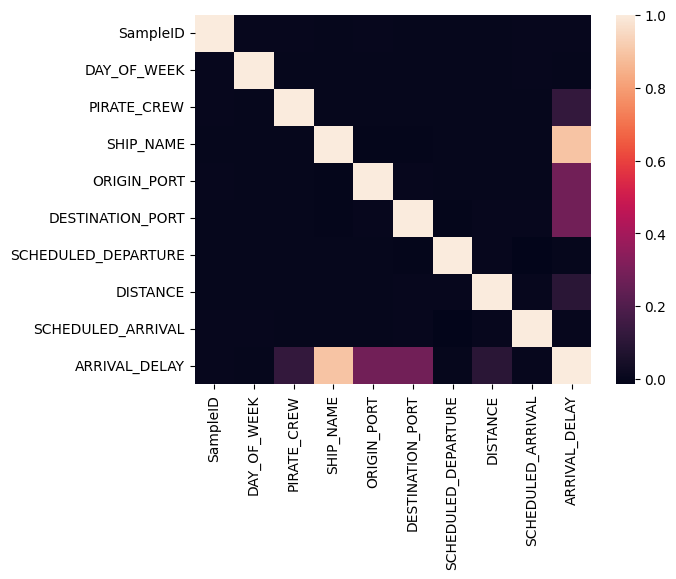

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(df_train.corr())
plt.show()

In [14]:
df_train.skew()

SampleID              -0.000465
DAY_OF_WEEK           -0.000333
PIRATE_CREW            1.118355
SHIP_NAME             -0.203834
ORIGIN_PORT           -0.113006
DESTINATION_PORT      -0.127209
SCHEDULED_DEPARTURE    0.000327
DISTANCE               1.406424
SCHEDULED_ARRIVAL     -0.001361
ARRIVAL_DELAY         -0.146720
dtype: float64

In [15]:
df_train.columns

Index(['SampleID', 'DAY_OF_WEEK', 'PIRATE_CREW', 'SHIP_NAME', 'ORIGIN_PORT',
       'DESTINATION_PORT', 'SCHEDULED_DEPARTURE', 'DISTANCE',
       'SCHEDULED_ARRIVAL', 'ARRIVAL_DELAY'],
      dtype='object')

In [16]:
features = ['DAY_OF_WEEK', 'PIRATE_CREW', 'SHIP_NAME', 'ORIGIN_PORT', 'DESTINATION_PORT', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'SCHEDULED_ARRIVAL']
target = 'ARRIVAL_DELAY'

X = df_train[features]
y = df_train[target]
X_final = df_test[features]

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=features)
X_final = pd.DataFrame(scaler.transform(X_final), columns=features)

X.head()

,DAY_OF_WEEK,PIRATE_CREW,SHIP_NAME,ORIGIN_PORT,DESTINATION_PORT,SCHEDULED_DEPARTURE,DISTANCE,SCHEDULED_ARRIVAL
0,-1.282513,-0.399164,0.843169,0.300304,1.378374,1.082102,1.004199,-0.453583
1,0.002753,-0.959608,0.783539,2.136817,-2.410385,-0.502232,0.446065,-1.419329
2,-1.925146,-0.979227,0.843169,-0.375096,1.192012,1.273183,1.905830,0.869216
3,0.002753,-0.721041,0.512783,0.626070,0.504871,-0.670149,-0.407817,0.995197
4,0.002753,-0.687292,0.844803,0.339524,-1.480820,-1.009774,0.609907,-1.091683


In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

model = LinearRegression()

cross_val_score(model, X, y, cv=3, scoring='neg_mean_absolute_error').mean()

-5.790473134031754

In [19]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [20]:
df_preds = pd.DataFrame({
    "subtaskID": 3,
    "datapointID": df_test.SampleID,
    "answer": y_preds
})

df_preds.head()

,subtaskID,datapointID,answer
0,3,170465,134.912662
1,3,142793,-56.728352
2,3,114956,82.740929
3,3,90284,-49.296125
4,3,105954,-42.999035


In [21]:
submission = pd.concat([df_1, df_2, df_preds])
submission

,subtaskID,datapointID,answer
0,1,1,39.313966
0,2,Abyssal Scoundrels,12.000000
1,2,Anchor Avengers,20.000000
2,2,Barnacle Six,14.000000
3,2,Davy Jones Locker,22.000000
...,...,...,...
57135,3,160621,73.323548
57136,3,253488,39.845619
57137,3,19424,68.462300
57138,3,80218,-30.874918


In [22]:
submission.to_csv("submission.csv", index=False)